In [13]:
!pip install mecab-python3
!pip install gensim
!pip install wordcloud
!pip install matplotlib
!pip install fugashi
!pip install unidic-lite
!python -m unidic download
!apt-get -y install fonts-noto-cjk

!pip install sentence-transformers fugashi unidic-lite
!pip install tf-keras

/usr/bin/sh: 1: python: not found
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
fonts-noto-cjk is already the newest version (1:20220127+repack1-1).
0 upgraded, 0 newly installed, 0 to remove and 25 not upgraded.


In [14]:
from gensim.models import Word2Vec
from wordcloud import WordCloud
import matplotlib.pyplot as plt
from typing import List
from fugashi import Tagger

def read_file(file_path: str) -> List[str]:
    with open(file_path, "r", encoding="utf-8") as f:
        lines = f.read().split("\n")
    return lines

def tokenize(text: str) -> List[str]:
    tagger = Tagger()
    return [w.surface for w in tagger(text)]

def create_embedding(words: List[str]) -> Word2Vec:
    model = Word2Vec([words], min_count=1, vector_size=100, window=5)
    return model

def create_wordcloud(model: Word2Vec):
    # Word2Vecモデルから単語頻度を取得（gensim4対応）
    freqs = {word: model.wv.get_vecattr(word, "count") for word in model.wv.key_to_index}
    
    # ストップワード設定
    stopwords = {
        "は","が","を","に","の","と","も","で","て","だ","な","です","ます",
        "する","した","して","いる","ある","なる","よう","ため",
        "これ","それ","あれ","ここ","そこ","そして", "、", "。"
    }
    
    # Stopwords 除去
    freqs = {k:v for k,v in freqs.items() if k not in stopwords}
    
    wordcloud = WordCloud(
        background_color="white",
        width=800,
        height=600,
        font_path="/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc"  # 文字化け対策
    ).generate_from_frequencies(freqs)

    plt.imshow(wordcloud)
    plt.axis("off")
    plt.show()


# 実行部
lines = read_file("日本語文書のベクトル埋め込み/マルチバース.txt")
all_text = "".join(lines)
words = tokenize(all_text)
model = create_embedding(words)
create_wordcloud(model)

FileNotFoundError: [Errno 2] No such file or directory: '日本語文書のベクトル埋め込み/マルチバース.txt'

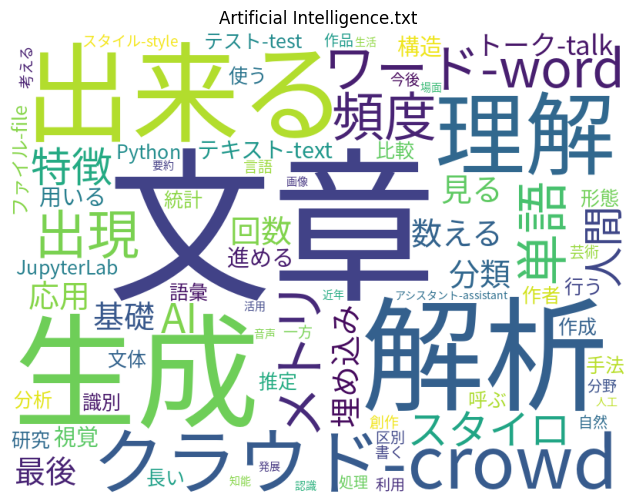

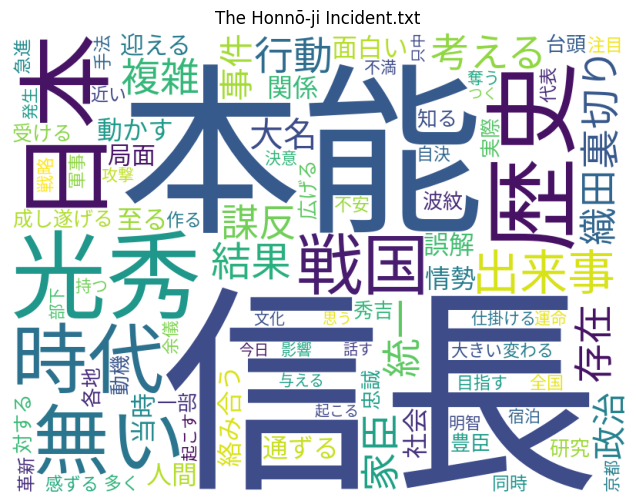

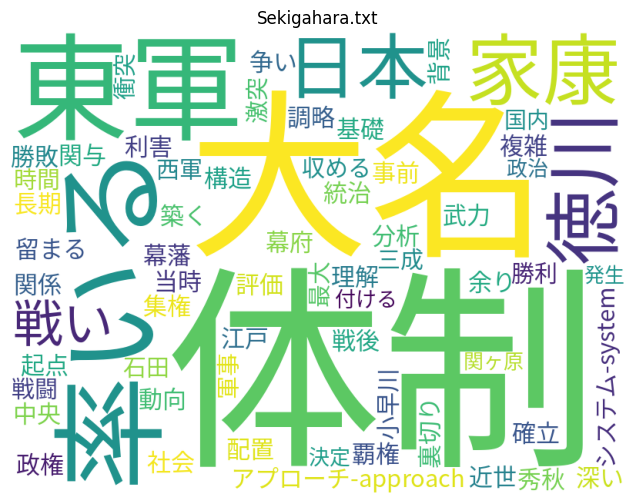

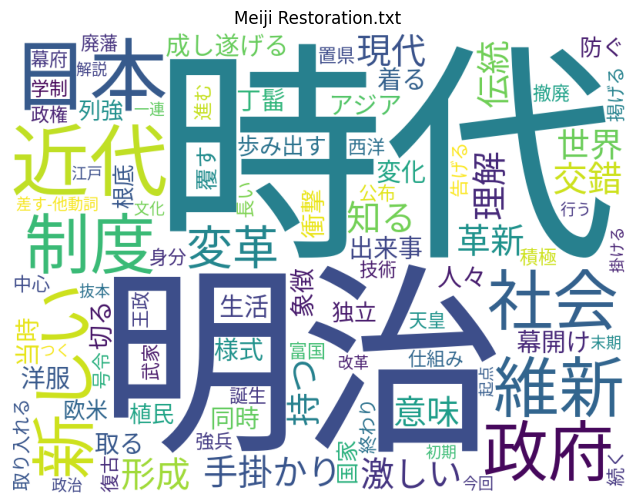

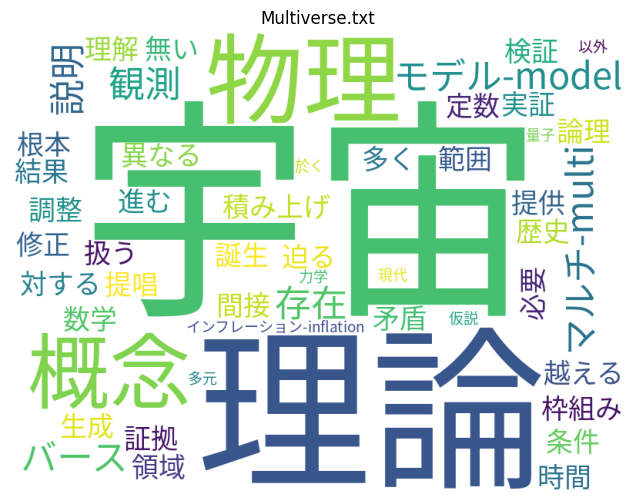

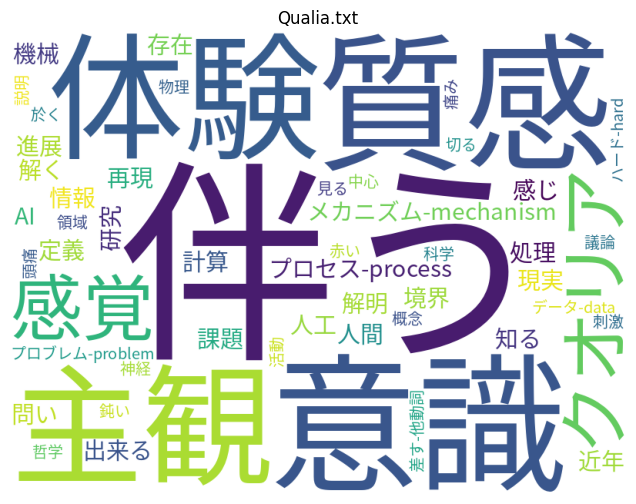

=== 文章ごとの単語頻度ベクトル ===
                             日本  信長  文章  時代  本能  歴史  宇宙  生成  理解  光秀  ...  奪う  \
Artificial Intelligence.txt   0   0   8   0   0   0   0   4   2   0  ...   0   
The Honnō-ji Incident.txt     5   9   0   3   6   5   0   0   0   5  ...   1   
Sekigahara.txt                2   0   0   0   0   0   0   0   1   0  ...   0   
Meiji Restoration.txt         3   0   0   4   0   0   0   0   1   0  ...   0   
Multiverse.txt                0   0   0   0   0   1   6   1   1   0  ...   0   
Qualia.txt                    0   0   0   0   0   0   0   0   0   0  ...   0   

                             不満  起こす  明智  部下  宿泊  京都  与える  影響  起こる  
Artificial Intelligence.txt   0    0   0   0   0   0    0   0    0  
The Honnō-ji Incident.txt     1    1   1   1   1   1    1   1    1  
Sekigahara.txt                0    0   0   0   0   0    0   0    0  
Meiji Restoration.txt         0    0   0   0   0   0    0   0    0  
Multiverse.txt                0    0   0   0   0   0    0   0    0  
Qua

In [22]:
from gensim.models import Word2Vec
from wordcloud import WordCloud
import matplotlib.pyplot as plt
from typing import List
from fugashi import Tagger
from collections import Counter
import pandas as pd
import numpy as np
import glob
import os

KEEP_POS = {"名詞", "動詞", "形容詞"}

KEEP_NOUN_POS1 = {
    "一般",
    "固有名詞",
    "サ変接続"
}

STOPWORDS = {
    "成る","為る","有る","因る","居る","言う","は","が","を","に","の","と","も","で","て","だ","な","です","ます",
    "する","した","して","いる","ある","なる","れる","られる","てる","たり","ん",
    "これ","それ","あれ","ここ","そこ","どこ","もの","こと","ほう",
    "及び","また","そして","しかし","さらに","ため","よう","ので","から",

    # 助詞類
    "へ","より","まで","とか","など","って","しか","だけ","でも","とも",

    # 活用語（頻出）
    "いる","ある","なる","できる","でき","せる","れる","られる",

    # 記号
    "、","。","・","「","」","『","』","（","）","(",")",
    "…","—","-",":",";","？","！","!", "?", "％", "%",

    # 空白扱い
    "\n","\t"," "
    }

# 元の関数＋拡張

def read_file(file_path: str) -> str:
    with open(file_path, "r", encoding="utf-8") as f:
        return f.read()

def tokenize(text: str) -> List[str]:
    tagger = Tagger()
    tokens = []

    for w in tagger(text):
        surface = w.surface
        base = w.feature.lemma
        pos1 = w.feature.pos1      # 名詞・動詞・形容詞…
        pos2 = w.feature.pos2      # 固有名詞 / 普通名詞 / サ変名詞…

        # 品詞フィルタ
        if pos1 not in {"名詞", "動詞", "形容詞"}:
            continue

        # 名詞の制限
        if pos1 == "名詞":
            if pos2 not in {"普通名詞", "固有名詞", "サ変名詞"}:
                continue

        # 原形決定ルール（★ここが重要）
        if pos1 == "名詞" and pos2 == "固有名詞":
            word = surface          # ← 漢字を守る
        else:
            word = base if base not in (None, "*") else surface

        if word is None:
            continue

        # ストップワード
        if word in STOPWORDS:
            continue

        # 為る・成る対策
        if pos1 == "動詞" and word in {"為る", "成る"}:
            continue

        # 1文字ノイズ
        if len(word) <= 1:
            continue

        tokens.append(word)

    return tokens


def create_embedding(words: List[str]) -> Word2Vec | None:
    if not words:
        return None
    return Word2Vec([words], min_count=1, vector_size=100, window=5)



def create_wordcloud(model: Word2Vec, title="WordCloud"):
    if len(model.wv) == 0:
        return {}

    freqs = {
        word: model.wv.get_vecattr(word, "count")
        for word in model.wv.key_to_index
    }

    if not freqs:
        return {}

    wc = WordCloud(
        background_color="white",
        width=800,
        height=600,
        font_path="/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc"
    ).generate_from_frequencies(freqs)

    plt.figure(figsize=(8,6))
    plt.title(title)
    plt.imshow(wc)
    plt.axis("off")
    plt.show()

    return freqs



def build_vocab(list_of_freqs, top_k=200):
    """全文章の単語頻度を合わせて上位語彙を作る"""
    global_counter = Counter()
    for freq in list_of_freqs:
        global_counter.update(freq)
    vocab = [w for w, c in global_counter.most_common(top_k)]
    return vocab

def freq_to_vector(freq, vocab):
    """頻度dict → 固定長ベクトルへ変換"""
    return np.array([freq.get(w, 0) for w in vocab])



# 複数ファイル一括処理

def analyze_folder(folder):
    file_paths = glob.glob(os.path.join(folder, "*.txt"))

    results = {}
    freq_list = []

    # --- 個別処理 ---
    for fp in file_paths:
        text = read_file(fp)
        words = tokenize(text)
        model = create_embedding(words)
        if model is None:
            continue
        
        title = os.path.basename(fp)
        freqs = create_wordcloud(model, title=title)
        
        results[title] = freqs
        freq_list.append(freqs)

    # --- 共通語彙の作成 ---
    vocab = build_vocab(freq_list, top_k=200)

    # --- ベクトル化 ---
    vectors = {title: freq_to_vector(results[title], vocab) for title in results}

    # DataFrame にまとめる
    df = pd.DataFrame.from_dict(vectors, orient="index", columns=vocab)

    return df

# 実行

df = analyze_folder("日本語文書のベクトル埋め込み")

print("=== 文章ごとの単語頻度ベクトル ===")
print(df)

# 類似度を見る例
from sklearn.metrics.pairwise import cosine_similarity
sim = cosine_similarity(df)
print("\n=== コサイン類似度 ===")
print(sim)


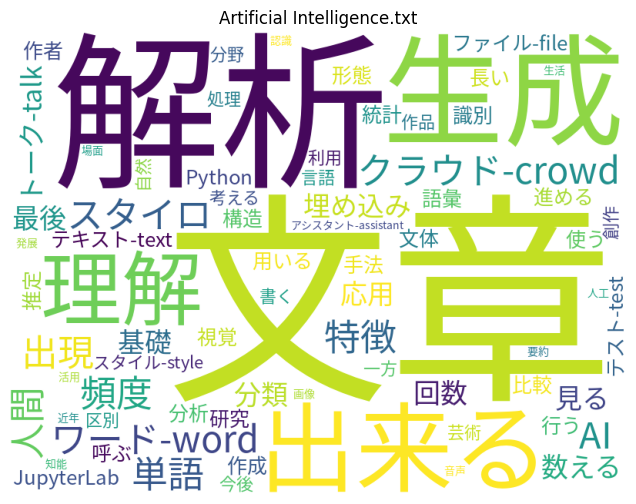

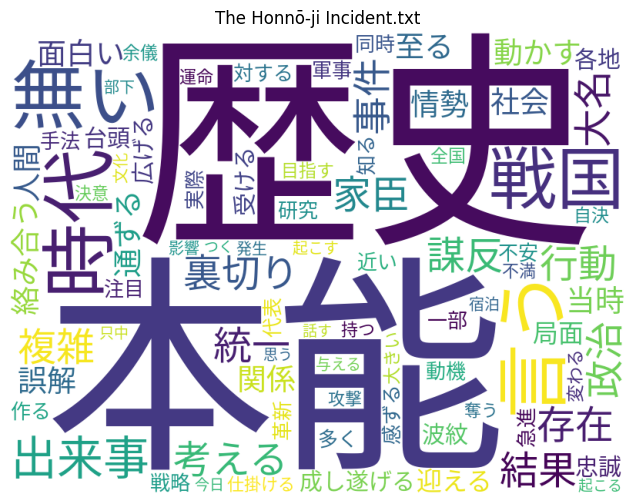

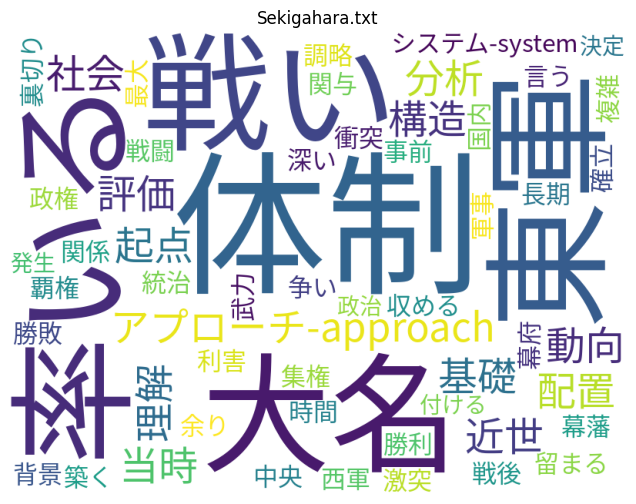

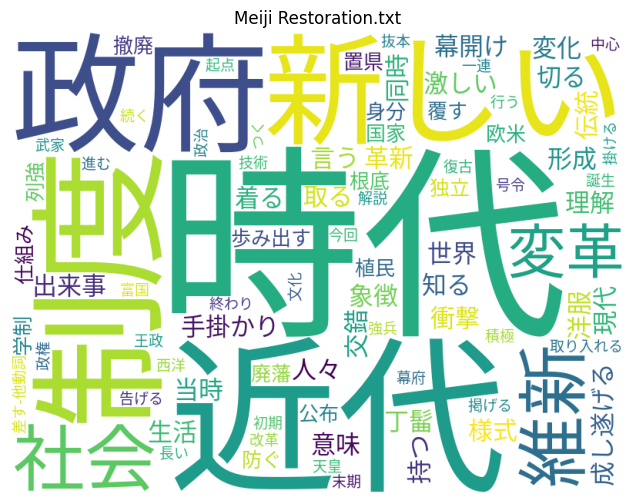

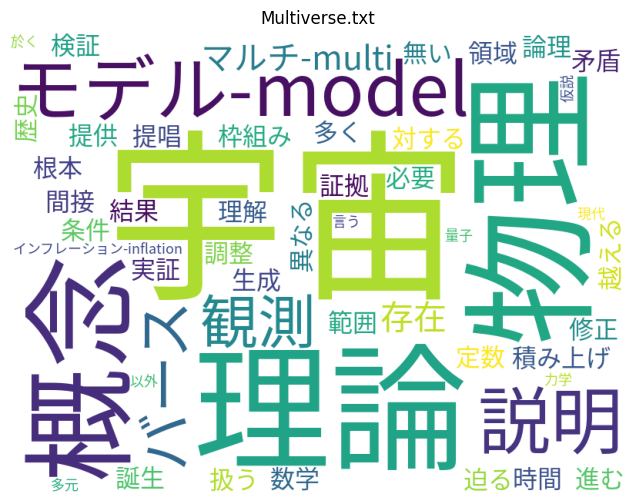

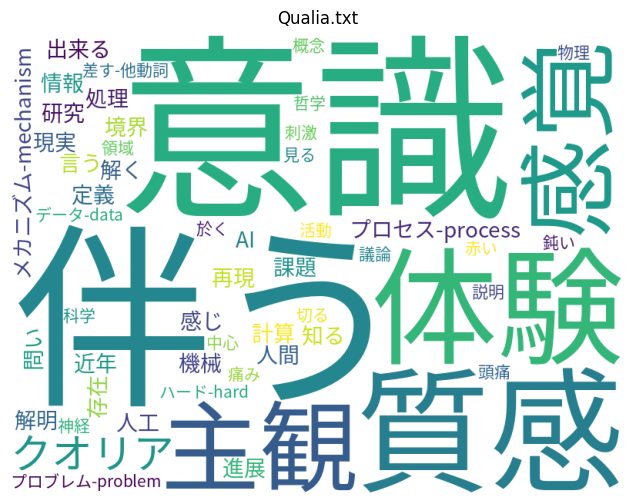

=== 文章ごとの単語頻度ベクトル ===
                             文章  言う  時代  歴史  宇宙  生成  理解  本能  存在  解析  ...  話す  \
Artificial Intelligence.txt   8   0   0   0   0   4   2   0   0   4  ...   0   
The Honnō-ji Incident.txt     0   3   3   5   0   0   0   5   2   0  ...   1   
Sekigahara.txt                0   1   0   0   0   0   1   0   0   0  ...   0   
Meiji Restoration.txt         0   1   4   0   0   0   1   0   0   0  ...   0   
Multiverse.txt                0   1   0   1   6   1   1   0   2   0  ...   0   
Qualia.txt                    0   1   0   0   0   0   0   0   1   0  ...   0   

                             今日  アプローチ-approach  近世  動向  配置  評価  システム-system  \
Artificial Intelligence.txt   0               0   0   0   0   0            0   
The Honnō-ji Incident.txt     1               0   0   0   0   0            0   
Sekigahara.txt                0               1   1   1   1   1            1   
Meiji Restoration.txt         0               0   0   0   0   0            0   
Multiverse.txt   

In [25]:
from gensim.models import Word2Vec
from wordcloud import WordCloud
import matplotlib.pyplot as plt
from typing import List
from fugashi import Tagger
from collections import Counter
import pandas as pd
import numpy as np
import glob
import os

KEEP_POS = {"名詞", "動詞", "形容詞"}

KEEP_NOUN_POS1 = {
    "一般",
    "固有名詞",
    "サ変接続"
}

STOPWORDS = {
    "成る","為る","有る","因る","居る","言う","は","が","を","に","の","と","も","で","て","だ","な","です","ます",
    "する","した","して","いる","ある","なる","れる","られる","てる","たり","ん",
    "これ","それ","あれ","ここ","そこ","どこ","もの","こと","ほう",
    "及び","また","そして","しかし","さらに","ため","よう","ので","から",

    # 助詞類
    "へ","より","まで","とか","など","って","しか","だけ","でも","とも",

    # 活用語（頻出）
    "いる","ある","なる","できる","でき","せる","れる","られる",

    # 記号
    "、","。","・","「","」","『","』","（","）","(",")",
    "…","—","-",":",";","？","！","!", "?", "％", "%",

    # 空白扱い
    "\n","\t"," "
    }

# 元の関数＋拡張

def read_file(file_path: str) -> str:
    with open(file_path, "r", encoding="utf-8") as f:
        return f.read()

def tokenize(text: str) -> List[str]:
    tagger = Tagger()
    tokens = []

    for w in tagger(text):
        surface = w.surface
        base = w.feature.lemma
        pos1 = w.feature.pos1      # 名詞・動詞・形容詞…
        pos2 = w.feature.pos2      # 固有名詞 / 普通名詞 / サ変名詞…

        # 品詞フィルタ
        if pos1 not in {"名詞", "動詞", "形容詞"}:
            continue

        # 名詞の制限
        if pos1 == "名詞":
            if pos2 not in {"普通名詞", "サ変名詞"}:
                continue

        # 原形決定ルール
        if pos1 == "名詞" and pos2 == "固有名詞":
            word = surface          # ← 漢字を守る
        else:
            word = base if base not in (None, "*") else surface

        if word is None:
            continue

        # ストップワード
        if word in STOPWORDS:
            continue

        # 為る・成る対策
        if pos1 == "動詞" and word in {"為る", "成る"}:
            continue

        # 1文字ノイズ
        if len(word) <= 1:
            continue

        tokens.append(word)

    return tokens


def create_embedding(words: List[str]) -> Word2Vec | None:
    if not words:
        return None
    return Word2Vec([words], min_count=1, vector_size=100, window=5)



def create_wordcloud(model: Word2Vec, title="WordCloud"):
    if len(model.wv) == 0:
        return {}

    freqs = {
        word: model.wv.get_vecattr(word, "count")
        for word in model.wv.key_to_index
    }

    if not freqs:
        return {}

    wc = WordCloud(
        background_color="white",
        width=800,
        height=600,
        font_path="/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc"
    ).generate_from_frequencies(freqs)

    plt.figure(figsize=(8,6))
    plt.title(title)
    plt.imshow(wc)
    plt.axis("off")
    plt.show()

    return freqs



def build_vocab(list_of_freqs, top_k=200):
    """全文章の単語頻度を合わせて上位語彙を作る"""
    global_counter = Counter()
    for freq in list_of_freqs:
        global_counter.update(freq)
    vocab = [w for w, c in global_counter.most_common(top_k)]
    return vocab

def freq_to_vector(freq, vocab):
    """頻度dict → 固定長ベクトルへ変換"""
    return np.array([freq.get(w, 0) for w in vocab])



# 複数ファイル一括処理

def analyze_folder(folder):
    file_paths = glob.glob(os.path.join(folder, "*.txt"))

    results = {}
    freq_list = []

    # --- 個別処理 ---
    for fp in file_paths:
        text = read_file(fp)
        words = tokenize(text)
        model = create_embedding(words)
        if model is None:
            continue
        
        title = os.path.basename(fp)
        freqs = create_wordcloud(model, title=title)
        
        results[title] = freqs
        freq_list.append(freqs)

    # --- 共通語彙の作成 ---
    vocab = build_vocab(freq_list, top_k=200)

    # --- ベクトル化 ---
    vectors = {title: freq_to_vector(results[title], vocab) for title in results}

    # DataFrame にまとめる
    df = pd.DataFrame.from_dict(vectors, orient="index", columns=vocab)

    return df

# 実行

df = analyze_folder("日本語文書のベクトル埋め込み")

print("=== 文章ごとの単語頻度ベクトル ===")
print(df)

# 類似度を見る例
from sklearn.metrics.pairwise import cosine_similarity
sim = cosine_similarity(df)
print("\n=== コサイン類似度 ===")
print(sim)


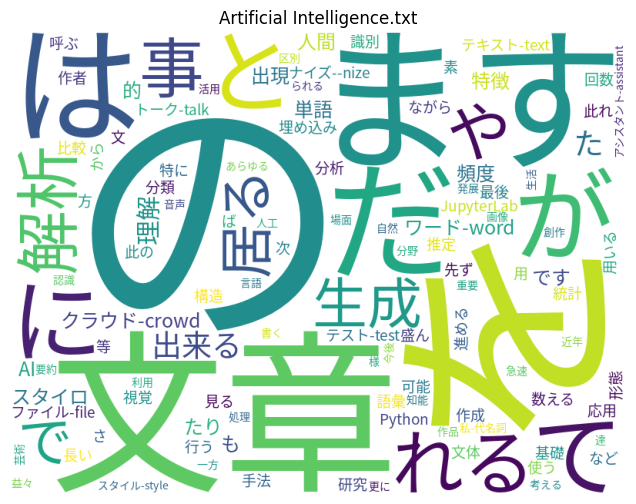

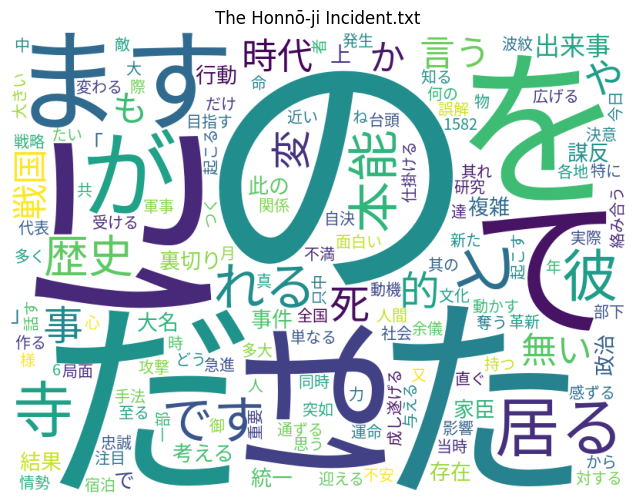

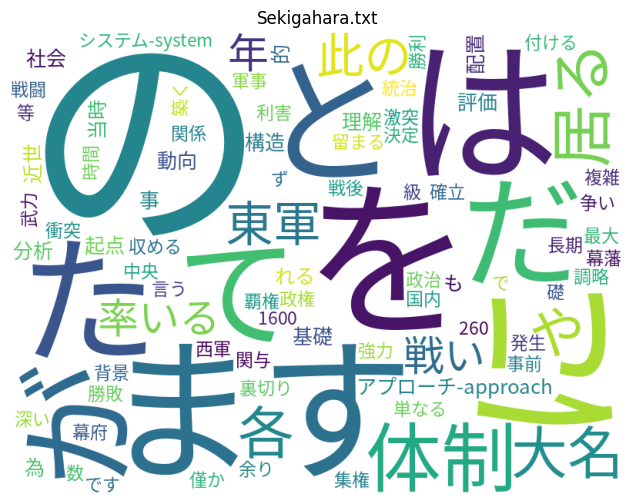

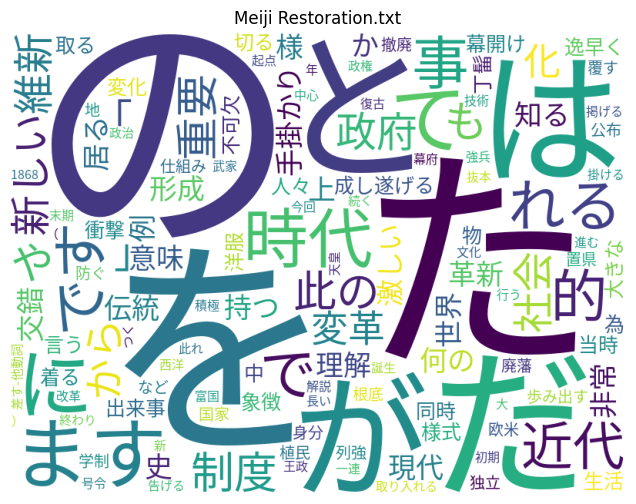

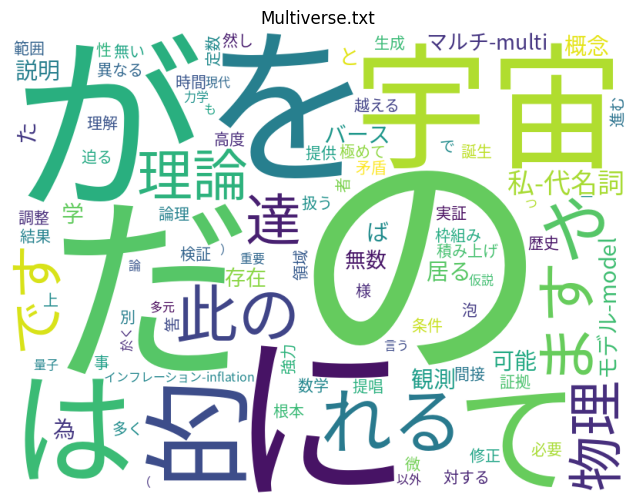

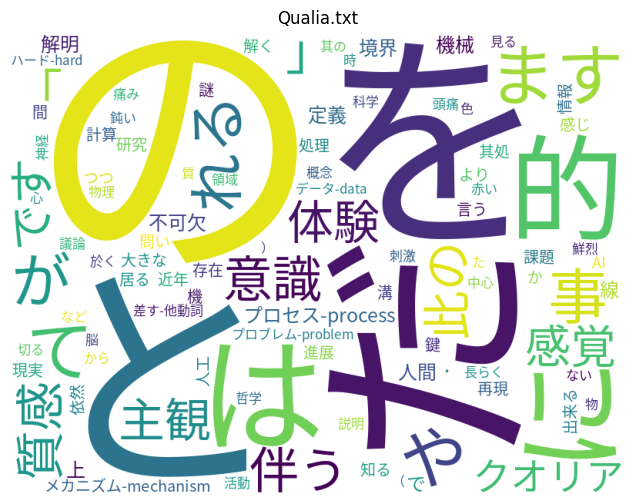

=== 文章ごとの単語頻度ベクトル ===
                              の   を   だ   に   は   た  ます   て  と   が  ...  盛ん  \
Artificial Intelligence.txt  16  11   7   5   7   3   7   5  5   6  ...   1   
The Honnō-ji Incident.txt    34  17  18  19  17  19  14  15  8  10  ...   0   
Sekigahara.txt               15   6   3   6   5   4   5   3  4   3  ...   0   
Meiji Restoration.txt        18  13   9   6   7  14   6   6  9   6  ...   0   
Multiverse.txt               14   6   8   7   5   2   3   5  2   7  ...   0   
Qualia.txt                   12   7   7   5   6   1   4   4  8   3  ...   0   

                             比較  スタイル-style  分野  言語  自然  られる  益々  今後  区別  
Artificial Intelligence.txt   1           1   1   1   1    1   1   1   1  
The Honnō-ji Incident.txt     0           0   0   0   0    0   0   0   0  
Sekigahara.txt                0           0   0   0   0    0   0   0   0  
Meiji Restoration.txt         0           0   0   0   0    0   0   0   0  
Multiverse.txt                0           0   0  

In [28]:
from gensim.models import Word2Vec
from wordcloud import WordCloud
import matplotlib.pyplot as plt
from typing import List
from fugashi import Tagger
from collections import Counter
import pandas as pd
import numpy as np
import glob
import os

KEEP_POS = {"名詞", "動詞", "形容詞"}

KEEP_NOUN_POS1 = {
    "一般",
    "固有名詞",
    "サ変接続"
}

STOPWORDS = {
    "成る","為る","有る","因る","居る","言う","は","が","を","に","の","と","も","で","て","だ","な","です","ます",
    "する","した","して","いる","ある","なる","れる","られる","てる","たり","ん",
    "これ","それ","あれ","ここ","そこ","どこ","もの","こと","ほう",
    "及び","また","そして","しかし","さらに","ため","よう","ので","から",

    # 助詞類
    "へ","より","まで","とか","など","って","しか","だけ","でも","とも",

    # 活用語（頻出）
    "いる","ある","なる","できる","でき","せる","れる","られる",

    # 記号
    "、","。","・","「","」","『","』","（","）","(",")",
    "…","—","-",":",";","？","！","!", "?", "％", "%",

    # 空白扱い
    "\n","\t"," "
    }

# 元の関数＋拡張

def read_file(file_path: str) -> str:
    with open(file_path, "r", encoding="utf-8") as f:
        return f.read()

def tokenize_stylo(text: str) -> List[str]:
    tagger = Tagger()
    tokens = []

    for w in tagger(text):
        surface = w.surface
        base = w.feature.lemma
        pos1 = w.feature.pos1
        pos2 = w.feature.pos2

        # 記号は除外
        if pos1 == "記号":
            continue

        # 固有名詞は除外（トピック殺し）
        if pos1 == "名詞" and pos2 == "固有名詞":
            continue

        # 原形 or 表層
        word = base if base not in (None, "*") else surface
        if word is None:
            continue

        # ストップワードは最小限に（★重要）
        if word in {"為る", "成る","因る", "有る", "、", "。"}:
            continue

        tokens.append(word)

    return tokens


def create_embedding(words: List[str]) -> Word2Vec | None:
    if not words:
        return None
    return Word2Vec([words], min_count=1, vector_size=100, window=5)



def create_wordcloud(model: Word2Vec, title="WordCloud"):
    if len(model.wv) == 0:
        return {}

    freqs = {
        word: model.wv.get_vecattr(word, "count")
        for word in model.wv.key_to_index
    }

    if not freqs:
        return {}

    wc = WordCloud(
        background_color="white",
        width=800,
        height=600,
        font_path="/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc"
    ).generate_from_frequencies(freqs)

    plt.figure(figsize=(8,6))
    plt.title(title)
    plt.imshow(wc)
    plt.axis("off")
    plt.show()

    return freqs



def build_vocab(list_of_freqs, top_k=200):
    """全文章の単語頻度を合わせて上位語彙を作る"""
    global_counter = Counter()
    for freq in list_of_freqs:
        global_counter.update(freq)
    vocab = [w for w, c in global_counter.most_common(top_k)]
    return vocab

def freq_to_vector(freq, vocab):
    """頻度dict → 固定長ベクトルへ変換"""
    return np.array([freq.get(w, 0) for w in vocab])



# 複数ファイル一括処理

def analyze_folder(folder):
    file_paths = glob.glob(os.path.join(folder, "*.txt"))

    results = {}
    freq_list = []

    # --- 個別処理 ---
    for fp in file_paths:
        text = read_file(fp)
        words = tokenize_stylo(text)
        model = create_embedding(words)
        if model is None:
            continue
        
        title = os.path.basename(fp)
        freqs = create_wordcloud(model, title=title)
        
        results[title] = freqs
        freq_list.append(freqs)

    # --- 共通語彙の作成 ---
    vocab = build_vocab(freq_list, top_k=200)

    # --- ベクトル化 ---
    vectors = {title: freq_to_vector(results[title], vocab) for title in results}

    # DataFrame にまとめる
    df = pd.DataFrame.from_dict(vectors, orient="index", columns=vocab)

    return df

# 実行

df = analyze_folder("日本語文書のベクトル埋め込み")

print("=== 文章ごとの単語頻度ベクトル ===")
print(df)

# 類似度を見る例
from sklearn.metrics.pairwise import cosine_similarity
sim = cosine_similarity(df)
print("\n=== コサイン類似度 ===")
print(sim)
